In [6]:

from pathlib import Path

output_dir = Path("data")
output_dir.mkdir(exist_ok=True)

books_clean.to_csv(
    output_dir / "books.csv",
    index=False,
    encoding="utf-8-sig"
)

ratings_clean.to_csv(
    output_dir / "ratings.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu dữ liệu đã xử lý:")
print("data/books.csv")
print("data/ratings.csv")


Đã lưu dữ liệu đã xử lý:
data/books.csv
data/ratings.csv


Matplotlib is building the font cache; this may take a moment.


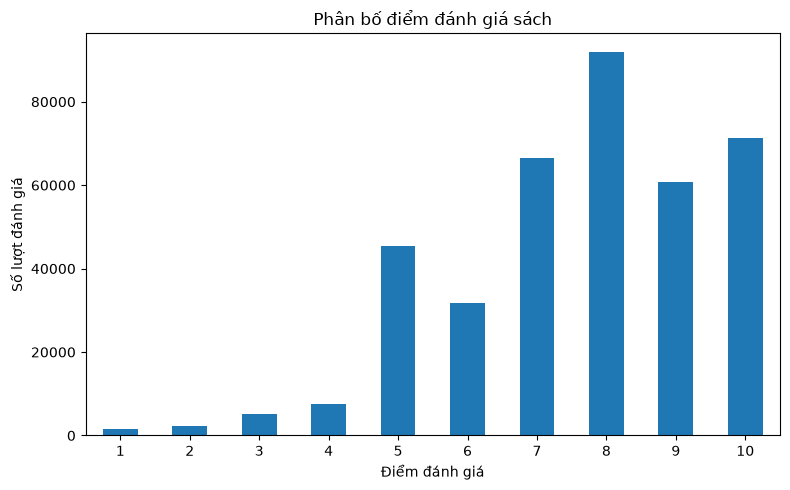

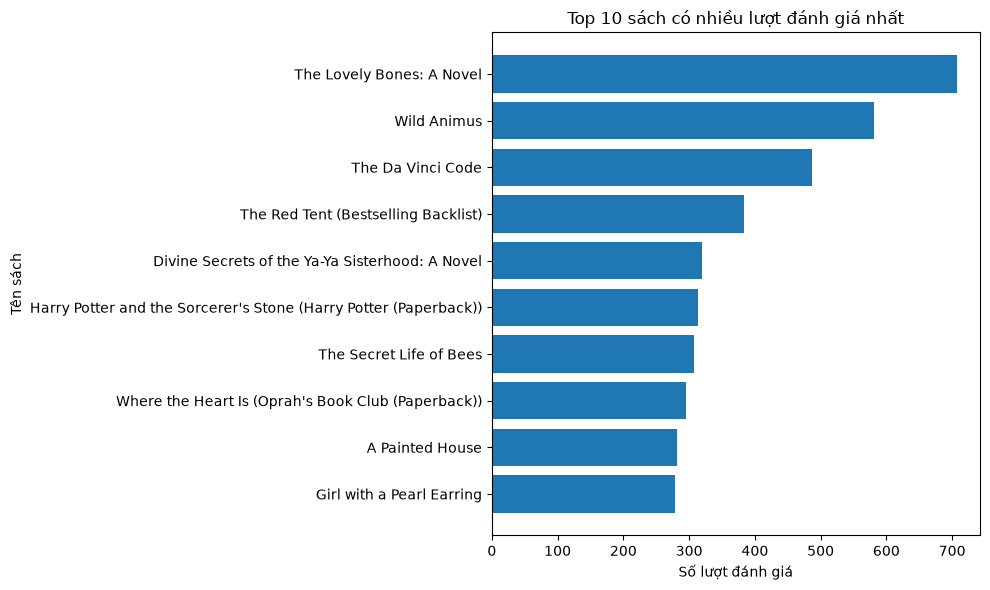

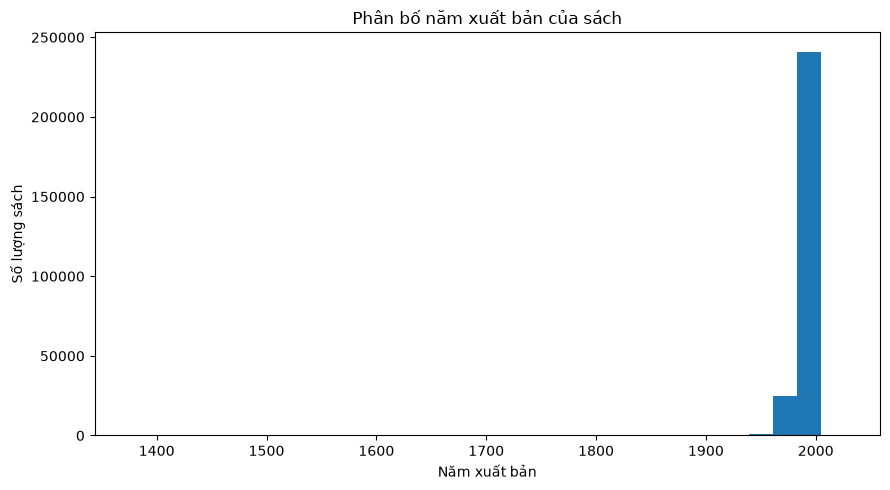

In [5]:

import matplotlib.pyplot as plt

# Biểu đồ 1: Phân bố điểm đánh giá thực
plt.figure(figsize=(8, 5))
ratings_clean["Book-Rating"].value_counts().sort_index().plot(
    kind="bar"
)
plt.title("Phân bố điểm đánh giá sách")
plt.xlabel("Điểm đánh giá")
plt.ylabel("Số lượt đánh giá")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Biểu đồ 2: Top 10 sách có nhiều lượt đánh giá nhất
top_books = (
    ratings_clean.groupby("ISBN")
    .size()
    .sort_values(ascending=False)
    .head(10)
    .rename("So_luot_danh_gia")
    .reset_index()
    .merge(
        books_clean[["ISBN", "Book-Title"]],
        on="ISBN",
        how="left"
    )
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_books["Book-Title"].iloc[::-1],
    top_books["So_luot_danh_gia"].iloc[::-1]
)
plt.title("Top 10 sách có nhiều lượt đánh giá nhất")
plt.xlabel("Số lượt đánh giá")
plt.ylabel("Tên sách")
plt.tight_layout()
plt.show()

# Biểu đồ 3: Phân bố năm xuất bản
years = books_clean["Year-Of-Publication"].dropna()

plt.figure(figsize=(9, 5))
plt.hist(years, bins=30)
plt.title("Phân bố năm xuất bản của sách")
plt.xlabel("Năm xuất bản")
plt.ylabel("Số lượng sách")
plt.tight_layout()
plt.show()


In [4]:

# BƯỚC 4: LÀM SẠCH DỮ LIỆU

import pandas as pd
import numpy as np

# Tạo bản sao để giữ nguyên dữ liệu gốc trong bộ nhớ
books_clean = books.copy()
ratings_clean = ratings.copy()

# 1. Chuẩn hóa các cột dạng văn bản
text_cols = ["ISBN", "Book-Title", "Book-Author", "Publisher"]

for col in text_cols:
    books_clean[col] = books_clean[col].astype("string").str.strip()

ratings_clean["ISBN"] = (
    ratings_clean["ISBN"].astype("string").str.strip()
)

# 2. Loại bỏ bản ghi không có ISBN hoặc tên sách
books_clean = books_clean.dropna(
    subset=["ISBN", "Book-Title"]
)

books_clean = books_clean[
    (books_clean["ISBN"] != "") &
    (books_clean["Book-Title"] != "")
].copy()

# 3. Điền thông tin còn thiếu bằng nhãn rõ ràng
books_clean["Book-Author"] = (
    books_clean["Book-Author"].fillna("Unknown")
)
books_clean["Publisher"] = (
    books_clean["Publisher"].fillna("Unknown")
)

# 4. Chuẩn hóa năm xuất bản và loại năm không hợp lệ
books_clean["Year-Of-Publication"] = pd.to_numeric(
    books_clean["Year-Of-Publication"],
    errors="coerce"
)

books_clean.loc[
    ~books_clean["Year-Of-Publication"].between(1000, 2026),
    "Year-Of-Publication"
] = np.nan

# Giữ một bản ghi cho mỗi ISBN
books_clean = books_clean.drop_duplicates(
    subset=["ISBN"], keep="first"
)

# 5. Làm sạch dữ liệu đánh giá
ratings_clean["Book-Rating"] = pd.to_numeric(
    ratings_clean["Book-Rating"],
    errors="coerce"
)

ratings_clean = ratings_clean.dropna(
    subset=["User-ID", "ISBN", "Book-Rating"]
)

# Chỉ giữ đánh giá thực từ 1 đến 10.
# Điểm 0 được xem là lượt đánh giá không có điểm số thực.
ratings_clean = ratings_clean[
    ratings_clean["Book-Rating"].between(1, 10)
].copy()

# Loại bỏ bản ghi lặp theo cặp người dùng - sách
ratings_clean = ratings_clean.drop_duplicates(
    subset=["User-ID", "ISBN"], keep="first"
)

# 6. Chỉ giữ đánh giá của những sách có trong bảng sách
valid_isbns = set(books_clean["ISBN"])
ratings_clean = ratings_clean[
    ratings_clean["ISBN"].isin(valid_isbns)
].copy()

# 7. Kiểm tra kết quả
print("SỐ DÒNG TRƯỚC VÀ SAU KHI LÀM SẠCH")
print("Books ban đầu:", len(books))
print("Books sau làm sạch:", len(books_clean))
print("Ratings ban đầu:", len(ratings))
print("Ratings sau làm sạch:", len(ratings_clean))

print("\nDữ liệu thiếu sau làm sạch:")
print("Books:\n", books_clean.isnull().sum())
print("Ratings:\n", ratings_clean.isnull().sum())

display(books_clean.head())
display(ratings_clean.head())


SỐ DÒNG TRƯỚC VÀ SAU KHI LÀM SẠCH
Books ban đầu: 271379
Books sau làm sạch: 271378
Ratings ban đầu: 1149780
Ratings sau làm sạch: 383853

Dữ liệu thiếu sau làm sạch:
Books:
 ISBN                      0
Book-Title                0
Book-Author               0
Year-Of-Publication    4630
Publisher                 0
Image-URL-S               0
Image-URL-M               0
Image-URL-L               0
dtype: int64
Ratings:
 User-ID        0
ISBN           0
Book-Rating    0
dtype: int64


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002.0,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001.0,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991.0,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999.0,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999.0,W. W. Norton & Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...


,User-ID,ISBN,Book-Rating
1,276726,0155061224,5
3,276729,052165615X,3
4,276729,0521795028,6
8,276744,038550120X,7
16,276747,0060517794,9


In [3]:
print("Phân bố điểm đánh giá:")
display(ratings["Book-Rating"].value_counts().sort_index())

print("\nThống kê điểm đánh giá:")
display(ratings["Book-Rating"].describe())

Phân bố điểm đánh giá:


Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64


Thống kê điểm đánh giá:


count    1.149780e+06
mean     2.866950e+00
std      3.854184e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      7.000000e+00
max      1.000000e+01
Name: Book-Rating, dtype: float64

In [2]:
# 1. Kiểm tra cấu trúc dữ liệu
print("=== BOOKS ===")
print(books.info())
print("\n5 dòng đầu:")
display(books.head())

print("\n=== RATINGS ===")
print(ratings.info())
display(ratings.head())

print("\n=== USERS ===")
print(users.info())
display(users.head())

# 2. Kiểm tra dữ liệu thiếu
print("\nSố giá trị thiếu trong BOOKS:")
display(books.isnull().sum())

print("\nSố giá trị thiếu trong RATINGS:")
display(ratings.isnull().sum())

print("\nSố giá trị thiếu trong USERS:")
display(users.isnull().sum())

# 3. Kiểm tra dòng trùng lặp
print("\nSố dòng trùng:")
print("Books:", books.duplicated().sum())
print("Ratings:", ratings.duplicated().sum())
print("Users:", users.duplicated().sum())

=== BOOKS ===
<class 'pandas.DataFrame'>
RangeIndex: 271379 entries, 0 to 271378
Data columns (total 8 columns):
 #   Column               Non-Null Count   Dtype
---  ------               --------------   -----
 0   ISBN                 271379 non-null  str  
 1   Book-Title           271379 non-null  str  
 2   Book-Author          271377 non-null  str  
 3   Year-Of-Publication  271379 non-null  int64
 4   Publisher            271377 non-null  str  
 5   Image-URL-S          271379 non-null  str  
 6   Image-URL-M          271379 non-null  str  
 7   Image-URL-L          271379 non-null  str  
dtypes: int64(1), str(7)
memory usage: 83.3 MB
None

5 dòng đầu:


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton & Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...



=== RATINGS ===
<class 'pandas.DataFrame'>
RangeIndex: 1149780 entries, 0 to 1149779
Data columns (total 3 columns):
 #   Column       Non-Null Count    Dtype
---  ------       --------------    -----
 0   User-ID      1149780 non-null  int64
 1   ISBN         1149780 non-null  str  
 2   Book-Rating  1149780 non-null  int64
dtypes: int64(2), str(1)
memory usage: 37.3 MB
None


,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6



=== USERS ===
<class 'pandas.DataFrame'>
RangeIndex: 278858 entries, 0 to 278857
Data columns (total 3 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   User-ID   278858 non-null  int64  
 1   Location  278858 non-null  str    
 2   Age       168096 non-null  float64
dtypes: float64(1), int64(1), str(1)
memory usage: 13.4 MB
None


...


Số giá trị thiếu trong RATINGS:


User-ID        0
ISBN           0
Book-Rating    0
dtype: int64


Số giá trị thiếu trong USERS:


User-ID          0
Location         0
Age         110762
dtype: int64


Số dòng trùng:
Books: 0
Ratings: 0
Users: 0


In [1]:
import pandas as pd
from pathlib import Path

data_dir = Path("data")

books = pd.read_csv(
    data_dir / "BX_Books.csv",
    sep=";",
    encoding="latin-1",
    on_bad_lines="warn"
)

ratings = pd.read_csv(
    data_dir / "BX-Book-Ratings.csv",
    sep=";",
    encoding="latin-1",
    on_bad_lines="warn"
)

users = pd.read_csv(
    data_dir / "BX-Users.csv",
    sep=";",
    encoding="latin-1",
    on_bad_lines="warn"
)

print("Books:", books.shape)
print("Ratings:", ratings.shape)
print("Users:", users.shape)

display(books.head())
display(ratings.head())
display(users.head())

Books: (271379, 8)
Ratings: (1149780, 3)
Users: (278858, 3)


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton & Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...


,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN
3,4,"porto, v.n.gaia, portugal",17.0
4,5,"farnborough, hants, united kingdom",NaN
